# Part 4 Historical Weather Integration and Statistical Analysis


Since Melt Gelato sells products such as gelato, milkshakes and coffee, I wanted to explore whether changes in weather conditions were associated with changes in customer demand.

For this analysis, I used historical weather data for Navan and combined it with the daily sales records. I focused on temperature, rainfall and sunshine to understand how sales varied under different weather conditions.

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display


HERE = Path.cwd()
ROOT = HERE.parent if HERE.name == "notebooks" else HERE
RAW_DIR = ROOT / "data" / "raw"
PROCESSED_DIR = ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)


In [4]:

df = pd.read_csv(
    PROCESSED_DIR / "cleaned_sales.csv",
    parse_dates=["sale_date"]
)

print("Cleaned sales dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Cleaned sales dataset loaded successfully!
Dataset shape: (122419, 49)


/var/folders/d_/d5ghnmqx2clg3rh4sk_g_n440000gn/T/ipykernel_71762/2982529649.py:1: DtypeWarning: Columns (8,21,24) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(


,Date,Time,Time Zone,Category,Item,Qty,Price Point Name,SKU,Modifiers Applied,Product Sales,...,Gross Sales_eur,event_type_clean,is_refund,is_payment,is_void,is_exact_duplicate,record_group,gross_check_difference,category_analysis,item_analysis
0,2025-11-30,22:01:14,London,Gelato,Gelato,1.0,2 Scoops,NaN,NaN,€5.50,...,5.5,payment,False,True,False,False,payment,0.0,Gelato,Gelato
1,2025-11-30,22:01:14,London,Toppings,Topping (Voided),10.0,Regular,NaN,NaN,€0.00,...,0.0,payment,False,True,True,False,void label,0.0,Toppings,Topping (Voided)
2,2025-11-30,21:34:18,London,Gelato,Gelato,1.0,2 Scoops,NaN,NaN,€5.50,...,5.5,payment,False,True,False,False,payment,0.0,Gelato,Gelato
3,2025-11-30,21:31:37,London,Milkshakes,Brownie Milkshake,1.0,Regular,NaN,NaN,€6.50,...,6.5,payment,False,True,False,False,payment,0.0,Milkshakes,Brownie Milkshake
4,2025-11-30,21:30:10,London,Milkshakes,Vanilla Milkshake,1.0,Regular,NaN,NaN,€6.00,...,6.0,payment,False,True,False,False,payment,0.0,Milkshakes,Vanilla Milkshake


In [5]:
daily_sales = pd.read_csv(PROCESSED_DIR / "daily_sales.csv", parse_dates=['sale_date'])
print("Loaded daily_sales:", daily_sales.shape)

Loaded daily_sales: (360, 11)


In [6]:
sales_lines = df.loc[df["is_payment"].astype(str).str.lower().eq("true") & ~df["is_void"].astype(str).str.lower().eq("true")].copy()

## 4.1 Setup, dates, and API settings

In [7]:
import requests
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

WEATHER_CACHE = PROCESSED_DIR / "melt_navan_historical_weather_2024_2025.csv"
LATITUDE, LONGITUDE = 53.6528, -6.6814  # approximate Navan location, not store sensor
START_DATE = daily_sales["sale_date"].min().strftime("%Y-%m-%d")
END_DATE = daily_sales["sale_date"].max().strftime("%Y-%m-%d")
print("Weather date range:", START_DATE, "to", END_DATE)


Weather date range: 2024-12-01 to 2025-11-30


## 4.2 Retrieve and cache daily historical weather

In [8]:
if WEATHER_CACHE.exists():
    weather = pd.read_csv(WEATHER_CACHE, parse_dates=["sale_date"])
    print("Loaded cached weather:", WEATHER_CACHE)
else:
    api_url = "https://archive-api.open-meteo.com/v1/archive"
    parameters = {
        "latitude": LATITUDE, "longitude": LONGITUDE,
        "start_date": START_DATE, "end_date": END_DATE,
        "daily": ",".join([
            "temperature_2m_mean", "temperature_2m_max", "temperature_2m_min",
            "precipitation_sum", "sunshine_duration"
        ]),
        "timezone": "Europe/Dublin"
    }
    response = requests.get(api_url, params=parameters, timeout=60)
    response.raise_for_status()
    payload = response.json()
    if "daily" not in payload:
        raise ValueError(f"Unexpected API response: {payload}")
    weather = pd.DataFrame(payload["daily"]).rename(columns={
        "time": "sale_date", "temperature_2m_mean": "temp_mean_c",
        "temperature_2m_max": "temp_max_c", "temperature_2m_min": "temp_min_c",
        "precipitation_sum": "rain_mm", "sunshine_duration": "sunshine_seconds"
    })
    weather["sale_date"] = pd.to_datetime(weather["sale_date"])
    weather["sunshine_hours"] = weather["sunshine_seconds"] / 3600
    weather.to_csv(WEATHER_CACHE, index=False)
    print("Downloaded and cached weather:", WEATHER_CACHE)

weather["sale_date"] = pd.to_datetime(weather["sale_date"])
weather = weather.sort_values("sale_date").reset_index(drop=True)
assert weather["sale_date"].is_unique, "Duplicate weather dates found"
display(weather.head())


Loaded cached weather: /Users/aakritiabhaysingh/Desktop/melt final/data/processed/melt_navan_historical_weather_2024_2025.csv


,sale_date,temp_mean_c,temp_max_c,temp_min_c,rain_mm,sunshine_seconds,sunshine_hours
0,2024-12-01,10.5,12.6,7.6,1.7,10713.48,2.975967
1,2024-12-02,5.0,8.3,-0.7,0.0,25330.85,7.036347
2,2024-12-03,1.9,5.7,-2.4,0.0,18000.00,5.000000
3,2024-12-04,6.9,11.6,1.5,5.7,0.00,0.000000
4,2024-12-05,8.3,11.2,5.9,11.4,0.00,0.000000


Preparing the Weather Data

I matched the weather information with Melt Gelato’s daily sales data using the date.

This allowed me to compare each day’s revenue with the weather conditions recorded on that day. I used refund-adjusted gross revenue to account for refunds when examining daily sales performance.

## 4.3 Validate and merge with observed sales dates

In [9]:
weather_columns = ["temp_mean_c", "temp_max_c", "temp_min_c", "rain_mm", "sunshine_hours"]
print("Weather days:", len(weather))
print("Missing weather values:")
display(weather[weather_columns].isna().sum().to_frame("missing"))

weather_sales = daily_sales[[
    "sale_date", "payment_gross_eur", "refund_adjusted_gross_eur",
    "transactions", "units_sold"
]].merge(weather[["sale_date"] + weather_columns], on="sale_date", how="left", validate="one_to_one")
assert len(weather_sales) == len(daily_sales), "Sales dates changed during merge"
if weather_sales[weather_columns].isna().any().any():
    raise ValueError("Some observed sales dates have missing weather; investigate before modelling")
weather_sales["weekday"] = weather_sales["sale_date"].dt.day_name()
weather_sales["month"] = weather_sales["sale_date"].dt.month.astype("category")
weather_sales["is_weekend"] = weather_sales["sale_date"].dt.dayofweek.ge(5).astype(int)
print("Matched observed sales days:", len(weather_sales))
display(weather_sales.head())


Weather days: 365
Missing weather values:


,missing
temp_mean_c,0
temp_max_c,0
temp_min_c,0
rain_mm,0
sunshine_hours,0


Matched observed sales days: 360


,sale_date,payment_gross_eur,refund_adjusted_gross_eur,transactions,units_sold,temp_mean_c,temp_max_c,temp_min_c,rain_mm,sunshine_hours,weekday,month,is_weekend
0,2024-12-01,1354.8,1354.8,137,345.0,10.5,12.6,7.6,1.7,2.975967,Sunday,12,1
1,2024-12-02,674.4,674.4,93,172.0,5.0,8.3,-0.7,0.0,7.036347,Monday,12,0
2,2024-12-03,878.1,878.1,102,215.0,1.9,5.7,-2.4,0.0,5.000000,Tuesday,12,0
3,2024-12-04,854.8,854.8,111,242.0,6.9,11.6,1.5,5.7,0.000000,Wednesday,12,0
4,2024-12-05,832.6,832.6,100,210.0,8.3,11.2,5.9,11.4,0.000000,Thursday,12,0


Exploring Weather and Daily Revenue

I created scatter plots to see how daily revenue varied with temperature, rainfall and sunshine.

The plots suggest that revenue generally increased on warmer and sunnier days, although there was considerable variation between individual days. The relationship with rainfall appeared less clear.

These observations helped me identify patterns worth investigating further through statistical analysis.

## 4.4 Visualise weather and daily sales (descriptive only)

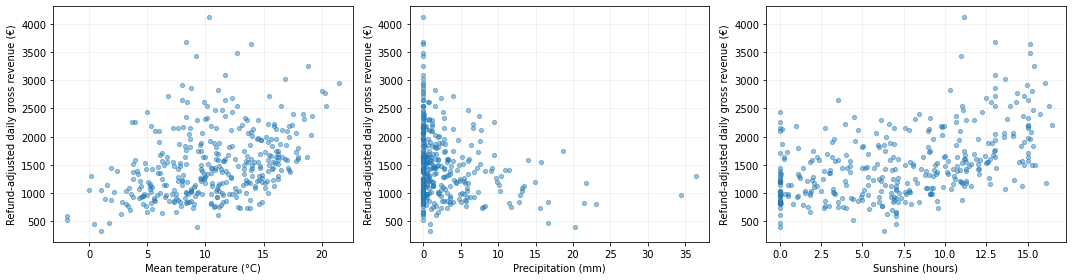

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, label in zip(
    axes,
    ["temp_mean_c", "rain_mm", "sunshine_hours"],
    ["Mean temperature (°C)", "Precipitation (mm)", "Sunshine (hours)"]
):
    ax.scatter(weather_sales[col], weather_sales["refund_adjusted_gross_eur"], alpha=0.45, s=18)
    ax.set_xlabel(label)
    ax.set_ylabel("Refund-adjusted daily gross revenue (€)")
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


### Correlation Analysis

To examine these relationships more closely, I calculated
Pearson and Spearman correlation coefficients.

Sunshine showed a moderate positive correlation with daily
revenue (Pearson r = 0.494), suggesting that sunnier days
were generally associated with higher sales.

However, correlation does not necessarily mean that weather
directly caused the changes in revenue. Other factors, such
as weekends, holidays and seasonal demand, may also have
contributed.

## 4.5 Pearson and Spearman correlations

- Pearson measures linear association
- Spearman measures monotonic association. 


In [11]:
from scipy.stats import pearsonr, spearmanr

correlation_rows = []
for col in weather_columns:
    x = weather_sales[col]
    y = weather_sales["refund_adjusted_gross_eur"]
    r, p = pearsonr(x, y)
    rho, p_s = spearmanr(x, y)
    correlation_rows.append({"weather_feature": col, "pearson_r": r,
                             "pearson_p": p, "spearman_rho": rho, "spearman_p": p_s})
correlations = pd.DataFrame(correlation_rows).sort_values("pearson_r", key=abs, ascending=False)
display(correlations.round(4))


,weather_feature,pearson_r,pearson_p,spearman_rho,spearman_p
4,sunshine_hours,0.4936,0.0,0.4920,0.0
1,temp_max_c,0.4630,0.0,0.4910,0.0
0,temp_mean_c,0.3827,0.0,0.4112,0.0
2,temp_min_c,0.2524,0.0,0.2907,0.0
3,rain_mm,-0.2293,0.0,-0.2126,0.0


## 4.6 Adjust for weekday and month using regression

We estimate associations with temperature, rainfall and sunshine while controlling for calendar effects. 
- Month indicators absorb some seasonality.
- Temperature and sunshine may be correlated interpret coefficients cautiously.


In [12]:
import statsmodels.formula.api as smf

regression_data = weather_sales.copy()
regression_data["weekday_number"] = regression_data["sale_date"].dt.dayofweek.astype("category")
regression_data["month_number"] = regression_data["sale_date"].dt.month.astype("category")

calendar_model = smf.ols(
    "refund_adjusted_gross_eur ~ C(weekday_number) + C(month_number)",
    data=regression_data
).fit(cov_type="HAC", cov_kwds={"maxlags": 7})
weather_model = smf.ols(
    "refund_adjusted_gross_eur ~ temp_mean_c + rain_mm + sunshine_hours + C(weekday_number) + C(month_number)",
    data=regression_data
).fit(cov_type="HAC", cov_kwds={"maxlags": 7})

print("Calendar-only adjusted R²:", round(calendar_model.rsquared_adj, 3))
print("Calendar + weather adjusted R²:", round(weather_model.rsquared_adj, 3))
display(pd.DataFrame({
    "coefficient": weather_model.params,
    "p_value_HAC": weather_model.pvalues,
    "CI_low": weather_model.conf_int()[0],
    "CI_high": weather_model.conf_int()[1]
}).loc[["temp_mean_c", "rain_mm", "sunshine_hours"]].round(4))
print("Note: In-sample adjusted R² is not forecasting accuracy.")


Calendar-only adjusted R²: 0.598
Calendar + weather adjusted R²: 0.712


,coefficient,p_value_HAC,CI_low,CI_high
temp_mean_c,43.8226,0.0000,27.9668,59.6785
rain_mm,-14.9898,0.0003,-23.0265,-6.9531
sunshine_hours,39.5845,0.0000,27.0043,52.1647


Note: In-sample adjusted R² is not forecasting accuracy.


## 4.7 Compare category-level weather associations

We use **payment-only** gross revenue for Gelato and Coffee, because category-specific refund allocation may be unreliable. This section describes associations and is not a forecast.

In [13]:
category_daily = (sales_lines.loc[
    sales_lines["category_analysis"].isin(["Gelato", "Coffee"])
].groupby(["sale_date", "category_analysis"])["Gross Sales_eur"]
 .sum().unstack(fill_value=0))

category_weather = (weather_sales[["sale_date"] + weather_columns]
    .merge(category_daily.reset_index(), on="sale_date", how="left", validate="one_to_one"))
for category in ["Gelato", "Coffee"]:
    category_weather[category] = category_weather[category].fillna(0)

category_corr = []
for category in ["Gelato", "Coffee"]:
    for feature in ["temp_mean_c", "rain_mm", "sunshine_hours"]:
        r, p = pearsonr(category_weather[feature], category_weather[category])
        category_corr.append({"category": category, "weather_feature": feature,
                              "pearson_r": r, "p_value_unadjusted": p})
display(pd.DataFrame(category_corr).round(4))


,category,weather_feature,pearson_r,p_value_unadjusted
0,Gelato,temp_mean_c,0.4789,0.0000
1,Gelato,rain_mm,-0.2356,0.0000
2,Gelato,sunshine_hours,0.5813,0.0000
3,Coffee,temp_mean_c,-0.0496,0.3485
4,Coffee,rain_mm,-0.2229,0.0000
5,Coffee,sunshine_hours,0.1413,0.0073


## 4.8 Diagnostics and model limitations

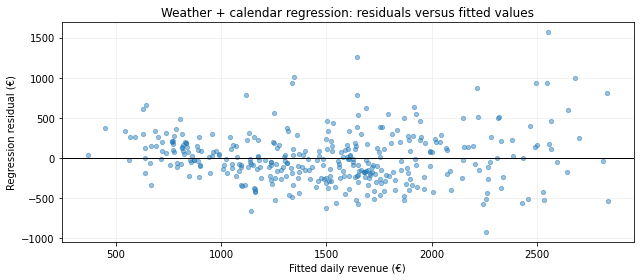

Weather dataset: 365 days
Observed sales days matched: 360
No-sales-record dates excluded: 5
Model R² (in-sample): 0.728

Dates without sales records:
2024-12-25
2024-12-26
2025-01-01
2025-01-02
2025-01-24


In [16]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(weather_model.fittedvalues, weather_model.resid, alpha=0.45, s=18)
ax.axhline(0, color="black", linewidth=1)
ax.set_xlabel("Fitted daily revenue (€)")
ax.set_ylabel("Regression residual (€)")
ax.set_title("Weather + calendar regression: residuals versus fitted values")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Identify dates with weather observations but no sales records
missing_sales_dates = (
    pd.DatetimeIndex(pd.to_datetime(weather["sale_date"]).dt.normalize())
    .difference(
        pd.DatetimeIndex(pd.to_datetime(weather_sales["sale_date"]).dt.normalize())
    )
)

print("Weather dataset:", len(weather), "days")
print("Observed sales days matched:", len(weather_sales))
print("No-sales-record dates excluded:", len(missing_sales_dates))
print("Model R² (in-sample):", round(weather_model.rsquared, 3))

print("\nDates without sales records:")
for date in missing_sales_dates:
    print(date.strftime("%Y-%m-%d"))

## Interpretation notes

Record the actual outputs rather than assuming weather increases or decreases demand:

1. **Data coverage:** How many weather dates were retrieved, and did all 360 observed POS dates match?
2. **Unadjusted relationships:** Which weather variable had the strongest Pearson/Spearman association with refund-adjusted daily gross revenue? Report coefficient and p-value.
3. **Adjusted relationships:** After controlling for month and weekday, which weather coefficients remain distinguishable from zero? Include confidence intervals and units.
4. **Added explanatory value:** Compare calendar-only and calendar-plus-weather adjusted R². This is **in-sample explanatory fit**, not evidence of better forecasting.
5. **Product comparison:** Do Gelato and Coffee show different unadjusted weather relationships? Avoid causal claims.
6. **Limitations:** Weather is an estimate for Navan, not an on-site measurement; one year of sales limits generalisation; holidays and promotions are not controlled; missing POS dates have unknown status; retained duplicate lines may affect totals; weather features may be collinear.


## 4.9 Export weather-enhanced daily dataset


In [17]:
weather_sales.to_csv(PROCESSED_DIR / "sales_weather.csv", index=False)
print("Saved:", PROCESSED_DIR / "sales_weather.csv")

Saved: /Users/aakritiabhaysingh/Desktop/melt final/data/processed/sales_weather.csv


### Key Takeaways

The analysis suggests that weather conditions are associated
with changes in Melt Gelato's daily sales, particularly
temperature and sunshine.

These findings could help the business prepare for periods
of potentially higher demand. However, weather should be
considered alongside historical sales patterns rather than
used as the only basis for operational decisions.

The next stage focuses on forecasting sales using historical
data and calendar-related information.